# 08 · Conditional breadth and portfolio composition

**Objective:** test computational scaling and the sensitivity of a locked hedge rule to breadth and company composition, while holding total initial underlying notional fixed.

The source panel retains 50 current issuer IDs. This run explicitly uses the **42 complete-history current survivors** as its master cohort and tests nested **3/10/25/40-name** books. Eight partial histories remain visible in the audit; no data are forward-filled.

**The full stage-7 research gate remains false.** Complete-history filtering through 2026 uses future availability relative to the 2020 calibration cutoff. Current membership/classification is not point-in-time historical membership. The actual historical section is a conditional static-equity diagnostic, not an option-overlay or listed-option backtest.

This completed report notebook reads a frozen, hashed simulation run. It does not rerun 72 policy cases on every Run All. Reproduce the full computation with `.venv/bin/python scripts/run_breadth_research.py`; the source functions and full protocol are retained.

## 1 · Load and verify the frozen study

The numerical run generated one 42-name master cube per dependence scenario, then selected each smaller book's columns. A common integer seed by itself would not preserve a stock's simulated histories if the number or order of simulated names changed.

The artifact hashes below cover all policy summaries, paired intervals, outcome archives and historical diagnostics. The protocol was recorded before policy outcomes were calculated. Inputs and policy were not reselected after viewing these results.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import json

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "hedging_harness" / "breadth.py").is_file():
    ROOT = ROOT.parent
assert (ROOT / "hedging_harness" / "breadth.py").is_file(), f"Wrong project root: {ROOT}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.run_breadth_research import plot_study

STUDY_DIR = ROOT / "results/breadth-20261106T020730752645Z"
manifest = json.loads((STUDY_DIR / "manifest.json").read_text())
protocol_bytes = (STUDY_DIR / "protocol.json").read_bytes()
protocol = json.loads(protocol_bytes)
assert sha256(protocol_bytes).hexdigest() == manifest["protocol_sha256"]
for name, digest in manifest["artifacts_sha256"].items():
    assert sha256((STUDY_DIR / name).read_bytes()).hexdigest() == digest, name
for name, digest in protocol["source_sha256"].items():
    assert sha256((ROOT / name).read_bytes()).hexdigest() == digest, name

for name, digest in protocol["data_sha256"].items():
    assert sha256((ROOT / name).read_bytes()).hexdigest() == digest, name
assert sha256(Path(protocol["locked_selection_path"]).read_bytes()).hexdigest() == protocol["locked_selection_sha256"]

summary = pd.read_csv(STUDY_DIR / "policy_summary.csv")
paired = pd.read_csv(STUDY_DIR / "paired_ES_differences.csv")
availability = pd.read_csv(STUDY_DIR / "availability_audit_all_50.csv")
master_scenarios = pd.read_csv(STUDY_DIR / "master_scenarios.csv")
historical_summary = pd.read_csv(STUDY_DIR / "historical_equity_summary.csv")
print("Frozen source and artifact hashes verified.")
print(f"Policy cases: {manifest['policy_cases']}; master simulations: {manifest['master_simulations']}")

Frozen source and artifact hashes verified.
Policy cases: 72; master simulations: 2


## 2 · Inspect the full availability audit

All 50 requested names remain in this table. The master includes 42 names with no missing observations over 2010–2026. The eight partial histories are excluded explicitly from this balanced numerical cohort, not removed from the source dataset.

The canonical order preserves JPM/PNC/GS and the original ten-name core. Seeded composition chains deliberately vary which names appear. Current classifications and current-survivor selection remain conditions of the study, not historical eligibility evidence.

In [2]:
assert len(availability) == 50
assert availability["included_in_complete_master"].sum() == 42
print("Excluded partial histories, with missing observations retained:")
display(availability.loc[~availability["included_in_complete_master"]])
print("Canonical master begins:", protocol["master_names"][:10])
print("Composition seeds:", protocol["composition_seeds"])

Excluded partial histories, with missing observations retained:


,name,observations,missing_observations,first_observed,last_observed,included_in_complete_master,reason
24,KKR,4233,3,2010-01-04,2026-11-04,False,excluded_partial_or_missing_history_no_fill
25,BAM,985,3251,2022-12-01,2026-11-04,False,excluded_partial_or_missing_history_no_fill
28,APO,3924,312,2011-03-30,2026-11-04,False,excluded_partial_or_missing_history_no_fill
32,HOOD,1324,2912,2021-07-29,2026-11-04,False,excluded_partial_or_missing_history_no_fill
35,PYPL,2852,1384,2015-07-06,2026-11-04,False,excluded_partial_or_missing_history_no_fill
40,ARES,3147,1089,2014-05-02,2026-11-04,False,excluded_partial_or_missing_history_no_fill
43,RKT,1570,2666,2020-08-06,2026-11-04,False,excluded_partial_or_missing_history_no_fill
45,COIN,1398,2838,2021-04-14,2026-11-04,False,excluded_partial_or_missing_history_no_fill


Canonical master begins: ['JPM', 'PNC', 'GS', 'BAC', 'WFC', 'C', 'USB', 'MS', 'SCHW', 'BK']
Composition seeds: [730711, 730712]


## 3 · Inspect the past-only calibration and master scenarios

The calibration uses 252 log returns through 2020-12-31 and a fixed 20% diagonal covariance shrinkage. Its inputs use no later prices. The **universe screen itself does use future availability**, so that separate limitation is not cured by a past-only covariance calculation.

The simulated stock/strike levels are normalized to 100, maturity is 63 sessions, and Q drift is a constant 4%. Realized-volatility estimates serve as model-pricing proxies; they are not market implied volatilities. The common-shock stress changes correlation with a positive-semidefinite convex mixture, while leaving marginal volatilities fixed.

In [3]:
vols = pd.read_csv(STUDY_DIR / "calibrated_annual_volatilities.csv", index_col=0)
print("Calibration cutoff:", protocol["calibration_cutoff"])
print("Last calibration observation:", protocol["calibration_last_observation"])
print("Covariance model:", protocol["covariance_model"])
display(vols.head(10))
display(master_scenarios)
assert master_scenarios["names"].eq(42).all()
assert master_scenarios["n_paths"].eq(protocol["n_paths"]).all()
np.testing.assert_allclose(summary["total_notional"], protocol["total_notional"])
print(f"All books retain ${protocol['total_notional']:,.0f} total initial underlying notional.")

Calibration cutoff: 2020-12-31
Last calibration observation: 2020-12-31
Covariance model: fixed 20 percent diagonal shrinkage of past sample daily covariance


,annual_volatility
JPM,0.543682
PNC,0.579440
GS,0.523288
BAC,0.585753
WFC,0.615228
C,0.680970
USB,0.584806
MS,0.571405
SCHW,0.529973
BK,0.489220


,scenario,master_scenario_id,names,n_paths,observations,path_storage_MB
0,calibrated_dependence,1b1de66d639ce3253c02d97729709ff5bd5133e0f072d9...,42,5000,64,107.52
1,synthetic_common_shock_stress,9ab69e46ab14b0f69b983a9d4a2d4586a10dcbf29b9dc6...,42,5000,64,107.52


All books retain $300,000 total initial underlying notional.


## 4 · Compare the locked policy with fixed benchmarks

The selected rule is **maturity_band_050**, read unchanged from the gate-1 selection record. It is compared with daily and five-session rebalancing at 5 bp. There is no breadth-specific threshold tuning or policy reselection.

The table displays the canonical chain; the full `summary` also includes two seeded nested composition chains. Lines in the chart are canonical books, and same-colored dots show the other compositions. Total notional stays fixed, while premiums, gamma, vega and sector mix can differ.

The original $500 expected financed-cost budget is evaluated again using a mean-cost interval's upper endpoint. It is an expected-cost screen, not a hard per-outcome cash or funding limit.

,scenario,breadth,policy,mean_pnl,pnl_std,loss_es95,mean_financed_cost,cost_mean_upper,cost_budget_upper_bound_passes
0,calibrated_dependence,3,maturity_band_050,-434.4049,2843.4879,6669.0869,488.0074,491.5956,True
1,calibrated_dependence,3,daily,-495.4137,2750.3446,6673.6766,545.5870,549.2810,False
2,calibrated_dependence,3,weekly,-278.9289,5914.1613,14178.9946,337.7407,340.3370,True
3,calibrated_dependence,10,maturity_band_050,-450.5944,2470.9075,5914.6392,488.3296,491.4847,True
4,calibrated_dependence,10,daily,-505.9257,2421.1595,5947.5065,545.9319,549.2075,False
5,calibrated_dependence,10,weekly,-270.7831,5256.0328,12512.5241,337.8023,340.2036,True
6,calibrated_dependence,25,maturity_band_050,-457.2340,1821.4839,4521.1266,487.5768,490.2458,True
7,calibrated_dependence,25,daily,-515.8194,1792.1257,4582.0542,545.2076,547.9817,False
8,calibrated_dependence,25,weekly,-300.5704,3944.3502,9539.4335,337.1190,339.1898,True
9,calibrated_dependence,40,maturity_band_050,-452.3557,1892.0692,4640.8407,487.9497,490.6157,True


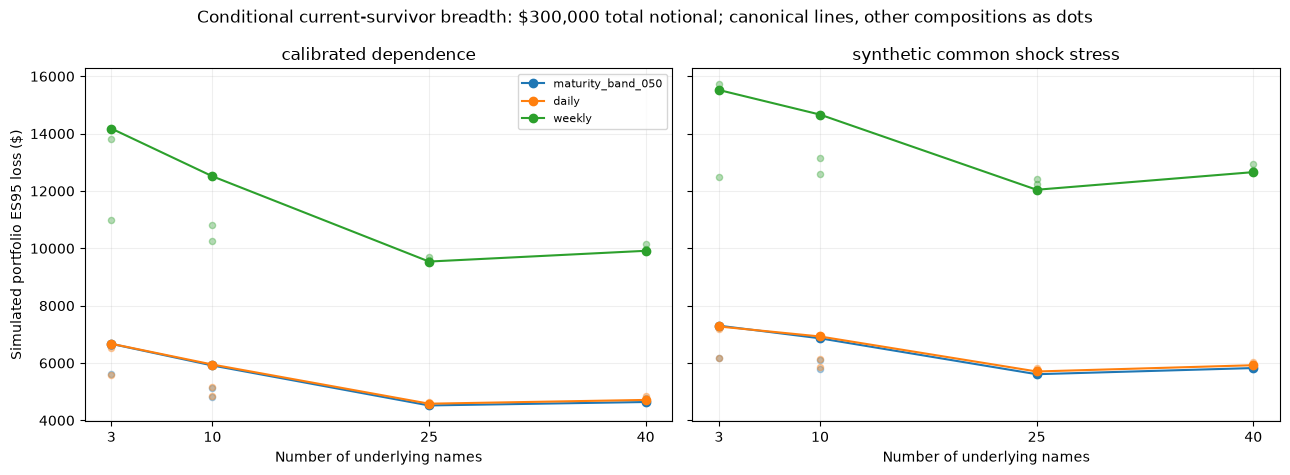

In [4]:
assert not protocol["policy_reselected"]
canonical = summary.loc[summary["composition"].eq("canonical")]
display(canonical[[
    "scenario", "breadth", "policy", "mean_pnl", "pnl_std", "loss_es95",
    "mean_financed_cost", "cost_mean_upper", "cost_budget_upper_bound_passes"
]].round(4))
fig = plot_study({"summary": summary, "protocol": protocol})
plt.show()

## 5 · Read uncertainty in the policy tail comparisons

Each paired interval concerns **ES(locked) minus ES(reference)** on the same simulated outcomes. A negative difference favors the locked rule under loss ES. It is not ES of the P&L difference.

There are 5,000 simulated outcomes and 250 tail outcomes per case. Five hundred paired resamples estimate simulation uncertainty conditional on the fixed model. The intervals exclude calibration/model uncertainty and are pointwise, not simultaneous evidence across every comparison. Composition variants share master innovations and are not independent experiments.

In [5]:
display(paired.loc[
    paired["composition"].eq("canonical") & paired["breadth"].eq(40),
    ["scenario", "left_policy", "right_policy", "estimate", "lower", "upper", "bootstrap_se"],
].round(4))
print("Negative estimates favor the locked policy under this conditional loss statistic.")

,scenario,left_policy,right_policy,estimate,lower,upper,bootstrap_se
6,calibrated_dependence,maturity_band_050,daily,-72.9917,-118.5153,-23.2455,23.3603
7,calibrated_dependence,maturity_band_050,weekly,-5273.1362,-5758.6692,-4847.8834,231.6640
30,synthetic_common_shock_stress,maturity_band_050,daily,-98.2440,-146.6873,-41.5345,27.1980
31,synthetic_common_shock_stress,maturity_band_050,weekly,-6832.4854,-7446.7390,-6245.4998,307.5891


Negative estimates favor the locked policy under this conditional loss statistic.


## 6 · Inspect actual static-equity breadth diagnostics

The additional price-only diagnostic uses 73 non-overlapping 20-session intervals in 2021–2026. Every interval holds equal initial dollar stock amounts at the same total $300,000 notional. It excludes derivatives, costs, financing and dividends.

There are only **four tail intervals** per historical ES95 calculation. Four-period circular block intervals address some serial dependence, but 40 companies during the same episode are not 40 independent crises. The cohort was selected using current survival and full future availability, so these are **conditional historical diagnostics, not untouched-universe OOS findings**.

Current-industry contributions use the same worst portfolio intervals and add to portfolio ES. Contemporary FMP industry labels are not verified historical GICS. This section does not claim overlay generalization from stage 6.

In [6]:
display(historical_summary.loc[historical_summary["composition"].eq("canonical"), [
    "breadth", "periods", "tail_observations", "mean_20_session_pnl", "pnl_std",
    "loss_es95", "es95_block_lower", "es95_block_upper", "industry_weight_hhi",
    "largest_current_industry_tail_contributor"
]].round(4))
periods = pd.read_csv(STUDY_DIR / "historical_equity_periods.csv", parse_dates=["origin", "target_start", "target_end"])
for _, group in periods.groupby(["composition", "breadth"]):
    group = group.sort_values("origin")
    assert (group["target_start"] > group["origin"]).all()
    assert (group["target_start"].iloc[1:].to_numpy() > group["target_end"].iloc[:-1].to_numpy()).all()
print("Historical return intervals are non-overlapping within each composition/breadth.")

,breadth,periods,tail_observations,mean_20_session_pnl,pnl_std,loss_es95,es95_block_lower,es95_block_upper,industry_weight_hhi,largest_current_industry_tail_contributor
0,3,73,4,4387.5006,20122.0295,38366.3984,25892.0529,46003.6904,0.3333,Banks - Regional
1,10,73,4,4189.9567,21201.7017,43544.6044,26856.9147,56050.8436,0.3000,Banks - Diversified
2,25,73,4,3894.9766,16565.6259,32446.3430,22823.4001,34905.6359,0.1200,Banks - Diversified
3,40,73,4,3846.8809,16312.2827,32525.4480,22010.7849,37365.3375,0.1013,Asset Management


Historical return intervals are non-overlapping within each composition/breadth.


## 7 · Keep the research gate explicit

The run establishes named master-path reuse, fixed-notional numerical comparisons, a locked-policy breadth test, explicit availability exclusions, and conditional static-equity diagnostics. It does not establish survivorship-safe historical membership, historical classifications or untouched derivative-overlay generalization.

Breadth is not monotonically protective: composition and concentration can outweigh ticker count. FMP does not provide historical option quotes for an executable listed-option study. The full research gate therefore remains false even though the bounded computation passes.

In [7]:
assert manifest["conditional_breadth_computation_passed"]
assert not manifest["full_stage7_gate_passed"]
assert not manifest["point_in_time_membership_verified"]
assert not manifest["overlay_generalization_evidence_included"]
record = {key: value for key, value in manifest.items() if key != "artifacts_sha256"}
notebook_path = ROOT / "Hedging_Study_Notebooks/08_breadth_and_composition.ipynb"
notebook_source = json.loads(notebook_path.read_text())
code_text = "\n\n".join(
    "".join(cell["source"]) for cell in notebook_source["cells"] if cell["cell_type"] == "code"
)
record["notebook_code_sha256"] = sha256(code_text.encode()).hexdigest()
print(json.dumps(record, indent=2))

{
  "generated_utc": "2026-11-06T02:08:02.184392+00:00",
  "protocol_sha256": "8523480cb63fc4fcbee114d0aa69a8db751762c9f732282b9034371f7222efe6",
  "protocol_hash_convention": "SHA256 of exact protocol.json file bytes including terminal newline",
  "source_sha256": {
    "scripts/run_breadth_research.py": "e3cf3ceb523f79a9e9e1b5403ac131378efa97ad5e2ea8ec9de31eb52a9a7338",
    "hedging_harness/breadth.py": "95f6d6cc8d3b1818884df8ed3e3409b3a29e5e4917d8b6c1b8367a508bbd692d",
    "hedging_harness/core.py": "6311f7ae6b6c035c6f3baf019006365cbafd8458974d6e2e23a6e1458d4b5c1e",
    "hedging_harness/policies.py": "e213dc91d6afd7391a2d03761cfd43de57396b98c0e2dd1531d339516b08a68c",
    "hedging_harness/risk_models.py": "7cfe9dfea5780c24db693937e67c1b2addc32803cee4377d9cdc0d7e596a8cd3",
    "hedging_harness/uncertainty.py": "c6379f05ecfd0470d5cae5045c10196e1ecf0870f0e02fa0ad0f4a50ee290ea6",
    "hedging_harness/legacy.py": "4dc0a27f694882769f9d7534ae6da82489f9a3c80843c02457668c2678ce417d",
    "Bla